# Performance Modeling

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import math, os, re, sys
from typing import Dict, List, Optional, Tuple
import warnings, glob
import scienceplots

In [2]:
# ── Shared style ────────────────────────────────────────────────────────────
plt.style.use(['science', 'grid', 'no-latex', 'high-contrast'])
plt.rcParams['pdf.fonttype'] = 42   # TrueType, not Type 3
plt.rcParams['ps.fonttype'] = 42

# Engine color/hatch palette (MMap=blue, IOUring=orange, SCISSOR=green)
ENGINE_STYLE = {
    'MMap':    {'color': '#1f77b4', 'hatch': '//'},
    'IOUring': {'color': '#ff7f0e', 'hatch': '..'},
    'SCISSOR': {'color': '#2ca02c', 'hatch': 'xx'},
}

FONT = {'title': 13, 'axis': 12, 'tick': 10, 'annot': 9, 'legend': 9}
FIG_SIZE_DEFAULT = (6, 3)
FIG_SIZE_WIDE    = (8, 4)
FIG_SIZE_SMALL   = (3.5, 2.5)

HC_COLORS = [
    '#000000', '#E69F00', '#56B4E9', '#009E73',
    '#F0E442', '#0072B2', '#D55E00', '#CC79A7',
    '#1f77b4', '#2ca02c'
]

fig_dir = "../figures"
os.makedirs(fig_dir, exist_ok=True)

## 2.1 IO Model

In [3]:
dir = "../data/motivation/benchmark_data"

filenames = {
    "ssd": f"{dir}/random_chks_io__ssd.csv",
    "pfs": f"{dir}/random_chks_io__pfs.csv",
    "hyb": f"{dir}/random_chks_io__hyb.csv"
}

missing = [f for f in filenames.values() if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f"Missing CSV files: {missing}. Place them in this directory and re-run.")

In [4]:
# Load CSVs and minimal validation
expected_cols = ["IOP", "Chunk size (B)", "Total size (B)", "Load time (s)", "Compare time (s)", "Throughput (GiB/s)"]

data: Dict[str, pd.DataFrame] = {}
for dev, fname in filenames.items():
    df = pd.read_csv(fname)
    missing_cols = [c for c in expected_cols if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{fname} is missing columns: {missing_cols}")
    df = df.dropna(subset=["IOP", "Chunk size (B)", "Load time (s)", "Throughput (GiB/s)"])
    df["IOP"] = df["IOP"].astype(int)
    df["chunk_bytes"] = df["Chunk size (B)"].astype(float)
    df["load_gib"] = (df["IOP"] * df["chunk_bytes"]) / (1024**3)
    mismatch = df[np.abs(df["IOP"] * df["chunk_bytes"] - df["Total size (B)"]) > 1.0]
    if len(mismatch) > 0:
        warnings.warn(f"{len(mismatch)} rows in {fname} have IOP * chunk != Total size (B) (tolerance 1 byte).")
    data[dev] = df
    print(f"{dev}: {len(df)} rows, chunk sizes: {sorted(df['Chunk size (B)'].unique())[:8]}...")

ssd: 855 rows, chunk sizes: [np.int64(4096), np.int64(6144), np.int64(8192), np.int64(12288), np.int64(16384), np.int64(24576), np.int64(32768), np.int64(49152)]...
pfs: 855 rows, chunk sizes: [np.int64(4096), np.int64(6144), np.int64(8192), np.int64(12288), np.int64(16384), np.int64(24576), np.int64(32768), np.int64(49152)]...
hyb: 855 rows, chunk sizes: [np.int64(4096), np.int64(6144), np.int64(8192), np.int64(12288), np.int64(16384), np.int64(24576), np.int64(32768), np.int64(49152)]...


In [5]:
def visualize(data):
    df_filt = data[data["total_gib"].isin([1, 2, 3, 4])]
    plt.figure(figsize=FIG_SIZE_DEFAULT)
    for size in [1, 2, 3, 4]:
        d = df_filt[df_filt["total_gib"] == size].sort_values("IOP")
        plt.plot(d["IOP"], d["Throughput (GiB/s)"], marker="o", label=f"{size} GiB")
    plt.xscale('log')
    plt.xlabel("IOP", fontsize=FONT['axis'])
    plt.ylabel("Throughput (GiB/s)", fontsize=FONT['axis'])
    plt.title("Throughput vs IOP for total size = 1GiB and 2GiB", fontsize=FONT['title'])
    plt.grid(True)
    plt.legend()
    plt.show()

In [6]:
# 2-variable model
def throughput_model_2d(data, a, b, c, d, e):
    iop, s = data
    return a * np.power(iop, b) * np.exp(-c * iop) * np.power(s, d) * np.exp(-e * s)


def run(input_df):
    df_data = input_df
    x_iop = df_data["IOP"].values
    x_size = df_data["total_gib"].values
    y = df_data["Throughput (GiB/s)"].values
    X = np.vstack((x_iop, x_size))

    p0 = [0.8, 0.2, 0.0001, 1.0, 0.00001]

    params, cov = curve_fit(throughput_model_2d, X, y, p0=p0, maxfev=30000)
    print("Estimated parameters:", params)

    y_pred = throughput_model_2d((x_iop, x_size), *params)
    mae = np.mean(np.abs(y - y_pred))
    rmse = np.sqrt(np.mean((y - y_pred)**2))
    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    r2 = 1 - ss_res / ss_tot

    print(f"MAE  = {mae:.4f}")
    print(f"RMSE = {rmse:.4f}")
    print(f"R\u00b2   = {r2:.4f}")

    plt.figure(figsize=FIG_SIZE_DEFAULT)
    xs = np.linspace(df_data["IOP"].min(), df_data["IOP"].max(), 300)
    for size_gib in [1, 2]:
        ys = throughput_model_2d((xs, np.full_like(xs, size_gib)), *params)
        plt.plot(xs, ys, label=f"Prediction     ({size_gib} GiB)", linewidth=2)
        df_slice = df_data[df_data["total_gib"] == size_gib].sort_values("IOP")
        plt.scatter(df_slice["IOP"], df_slice["Throughput (GiB/s)"],
                    alpha=0.8, s=40, label=f"Groundtruth ({size_gib} GiB)")

    plt.xscale('log')
    plt.xlabel("IOP", fontsize=FONT['axis'])
    plt.ylabel("Throughput (GiB/s)", fontsize=FONT['axis'])
    plt.grid(True)
    plt.legend()
    plt.show()
    return params

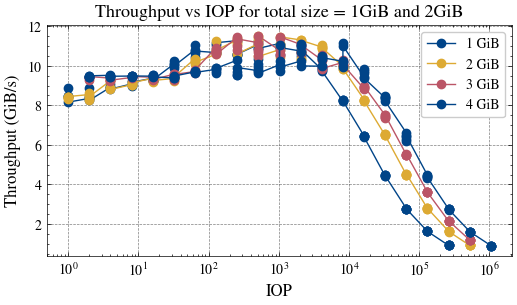

Estimated parameters: [ 1.12574778e+01 -5.58077466e-03  1.82020615e-05  1.63425820e-01
  7.47837197e-02]
MAE  = 1.4853
RMSE = 1.7965
R²   = 0.6809


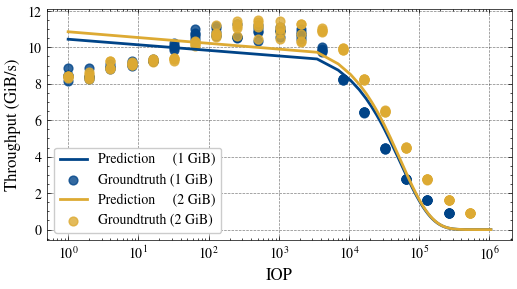

In [7]:
select_ssd_df = data['ssd']
select_ssd_df["total_bytes"] = select_ssd_df["Total size (B)"]
select_ssd_df["total_mib"] = select_ssd_df["Total size (B)"] / (1024**2)
select_ssd_df["total_gib"] = select_ssd_df["Total size (B)"] / (1024**3)
visualize(select_ssd_df)
ssd_params = run(select_ssd_df)

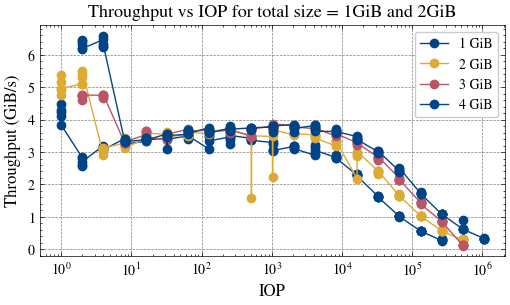

Estimated parameters: [ 4.28877775e+00 -3.32507510e-02  7.26028655e-06  4.54310243e-01
  1.37324064e-01]
MAE  = 0.3580
RMSE = 0.4658
R²   = 0.8879


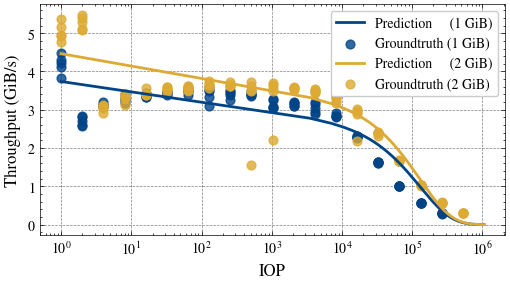

In [8]:
select_pfs_df = data['pfs']
select_pfs_df["total_mib"] = select_pfs_df["Total size (B)"] / (1024**2)
select_pfs_df["total_gib"] = select_pfs_df["Total size (B)"] / (1024**3)
visualize(select_pfs_df)
pfs_params = run(select_pfs_df)

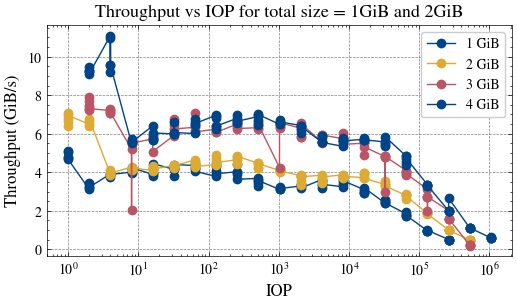

Estimated parameters: [ 4.26436889e+00 -3.46683860e-02  4.34919067e-06  3.85860676e-01
 -2.72297329e-02]
MAE  = 0.4683
RMSE = 0.6175
R²   = 0.9151


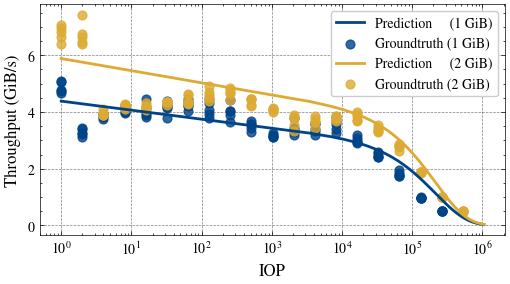

In [9]:
select_hyb_df = data['hyb']
select_hyb_df["total_mib"] = select_hyb_df["Total size (B)"] / (1024**2)
select_hyb_df["total_gib"] = select_hyb_df["Total size (B)"] / (1024**3)
visualize(select_hyb_df)
hyb_params = run(select_hyb_df)

In [10]:
def predict_throughput(params, iop_list, size_gib_list):
    """Predict throughput for arbitrary vectors of IOP and size (GiB)."""
    iop_arr = np.array(iop_list, dtype=float)
    size_arr = np.array(size_gib_list, dtype=float)
    return throughput_model_2d((iop_arr, size_arr), *params)

In [11]:
iops = [1024, 4096, 5000, 7000]
sizes_gib = [1, 1, 2, 4]

preds_ssd = predict_throughput(ssd_params, iops, sizes_gib)
preds_pfs = predict_throughput(pfs_params, iops, sizes_gib)
preds_hyb = predict_throughput(hyb_params, iops, sizes_gib)
preds_ssd, preds_pfs, preds_hyb

(array([9.86434745, 9.25601546, 9.45175526, 8.77256532]),
 array([2.94693765, 2.75210925, 3.24382445, 3.29135794]),
 array([3.43071062, 3.22633273, 4.28529162, 5.79353697]))

In [12]:
ssd_params, pfs_params, hyb_params

(array([ 1.12574778e+01, -5.58077466e-03,  1.82020615e-05,  1.63425820e-01,
         7.47837197e-02]),
 array([ 4.28877775e+00, -3.32507510e-02,  7.26028655e-06,  4.54310243e-01,
         1.37324064e-01]),
 array([ 4.26436889e+00, -3.46683860e-02,  4.34919067e-06,  3.85860676e-01,
        -2.72297329e-02]))

## 2.2 Compute Model

In [13]:
def fit_compute_time(
    df, test_size=0.2, xcols=['Work per core (B)'],
    ycol='Iteration compute throughput (GiB/s)',
    r2_threshold=0.9, max_attempts=1000
):
    X = df[xcols].values
    y = df[ycol].values
    results = []
    attempts = 0

    while attempts < max_attempts:
        attempts += 1
        X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=test_size)
        X_train_log = np.log(X_train)
        y_train_log = np.log(y_train)
        X_val_log = np.log(X_val)
        y_val_log = np.log(y_val)

        model = LinearRegression()
        model.fit(X_train_log, y_train_log)
        y_pred_log = model.predict(X_val_log)

        mse = mean_squared_error(y_val_log, y_pred_log)
        r2 = r2_score(y_val_log, y_pred_log)

        if r2 > r2_threshold:
            results.append({
                'mse': mse, 'r2': r2,
                'intercept': model.intercept_,
                'slope': model.coef_[0] if len(xcols) == 1 else model.coef_,
                'attempt': attempts
            })

    if not results:
        print(f"No models found with R\u00b2 > {r2_threshold} after {max_attempts} attempts.")
        return None

    best_result = min(results, key=lambda r: r['mse'])
    print(f"Found suitable model on attempt #{best_result['attempt']}")
    print(f"  R\u00b2 Score:  {best_result['r2']:.4f}")
    print(f"  MSE:       {best_result['mse']:.4f}")
    return best_result['slope'], best_result['intercept']


def compute_model(batch_size, slope, intercept):
    x_vals = np.array(batch_size)
    return np.exp(slope * np.log(x_vals) + intercept)

In [14]:
compute_time_file = f"{dir}/compute_benchmark.csv"
compute_df = pd.read_csv(compute_time_file)
compute_df['Work per core (B)'] = (compute_df['Work size (B)'] / compute_df['Nthreads']).astype(int)
compute_df['Iteration time (s)'] = compute_df['Compute time (ms)'] / 1000.0
main_cols = ['Work per core (B)', 'Iteration time (s)']
compute_df = compute_df.groupby(['Work per core (B)'], as_index=False)[['Iteration time (s)']].mean()
compute_df = compute_df[main_cols]
len(compute_df)

24

In [15]:
compute_slope, compute_intercept = fit_compute_time(
    compute_df, xcols=['Work per core (B)'], ycol='Iteration time (s)'
)

Found suitable model on attempt #884
  R² Score:  0.9972
  MSE:       0.0249


In [16]:
compute_slope, compute_intercept

(np.float64(0.744048909285208), np.float64(-17.016983331494604))